# Notebook 13: Data Validation, Legal Citations & Sensor Observability Specification
### DAT535 Data-Driven Decision Making | Medallion Lakehouse Integrity Ledger
**Author**: Group 13 | **Kernel**: `dat535` Python Kernel | **Architecture**: Medallion (Bronze $\rightarrow$ Silver $\rightarrow$ Gold)

---

## Executive Summary & Rigorous Grounding

In production data engineering, data cleaning rules cannot be arbitrary heuristic guesses or convenient shortcuts. Every validation boundary, physical threshold, quarantine filter, and categorical domain must have a **factual, legal, physical, or empirical basis**, backed by official primary sources.

This specification notebook provides:
1. **Primary Source Citations & Direct Links**: Official legal statutes ([NYC Charter](https://codelibrary.amlegal.com/codes/newyorkcity/latest/NYCcharter/0-0-0-1)), municipal agency directories ([MOCS Agency Acronyms](https://www.nyc.gov/site/mocs/reporting/agency-acronyms.page)), and international meteorological standards ([World Meteorological Organization](https://library.wmo.int/records/item/41650-guide-to-instruments-and-methods-of-observation) & [NOAA NCEI](https://www.weather.gov/okx/CentralParkHistorical)).
2. **The `unique_key` Empirical Proof**: Direct verification resolving why `unique_key` is not strictly 8 digits across 20+ years of NYC 311 data, but rather an auto-incrementing positive 64-bit integer ($\mathbb{Z}^+ > 0$).
3. **The Pre-2003 & Epoch Reality**: Why NYC 311 did not exist before March 2003, what causes pre-2003 timestamps (Unix epoch `1970` resets vs. legacy agency migrations), and why **quarantining preserves data instead of discarding it**.
4. **Data Observability Architecture**: Why corrupt values are masked to `NaN` in Silver to protect Gold aggregations, paired with a persistent **Sensor Anomaly Audit Ledger** (`sensor_anomaly_ledger.parquet`) and row-level `quality_audit_notes` to guarantee zero information loss.
5. **Live Empirical Verification**: Direct queries and visualizations verifying every single validation rule against our actual NYC 311 and Open-Meteo ERA5-Land datasets.


In [1]:
import os
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Adjust workspace root
PROJECT_ROOT = Path("..").resolve() if Path("..").joinpath("src").exists() else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.silver.config import (
    NYC_311_LAUNCH_DATE,
    NYC_COUNCIL_DISTRICT_MIN,
    NYC_COUNCIL_DISTRICT_MAX,
    KNOWN_NYC_AGENCIES,
    VALID_WMO_WEATHER_CODES,
    WEATHER_HARD_LIMITS,
    WEATHER_EXTREME_THRESHOLDS,
    NYC_STATE_PLANE_BOUNDS,
    NYC_METRO_ZIP_PREFIXES,
    SENSOR_ANOMALY_LEDGER_PATH,
    SILVER_DIR,
    BRONZE_DIR,
    QUALITY_DIR,
)

print(f"Environment successfully initialized.")
print(f"Project Root: {PROJECT_ROOT}")
print(f"Quality Directory: {QUALITY_DIR}")
print(f"Sensor Anomaly Ledger Path: {SENSOR_ANOMALY_LEDGER_PATH}")


Environment successfully initialized.
Project Root: C:\Media\UiS\DAT535
Quality Directory: C:\Media\UiS\DAT535\data\metadata\quality
Sensor Anomaly Ledger Path: C:\Media\UiS\DAT535\data\metadata\quality\sensor_anomaly_ledger.parquet


---
## 1. Primary Key (`unique_key`): Empirical Proof & Historical Progression

### The Question:
> *"Are you sure every `10000000 <= unique_key <= 99999999` is inside this range? On what basis?"*

### The Empirical Findings Across 20+ Years of NYC 311:
Hardcoding an 8-digit range (`10000000 <= unique_key <= 99999999`) is an **unsubstantiated assumption** derived solely from the recent 2020–present snapshot. 

NYC Open Data uses an auto-incrementing integer primary key generated by the Socrata platform. To determine the true domain, we queried historical NYC 311 dataset endpoints directly on the Socrata SODA API:
* **2004 Dataset ([`sqcr-6mww`](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-for-2004/sqcr-6mww))**: Early complaints launched with **7-digit keys** (e.g., `unique_key = 4705298`).
* **2010–2019 Dataset ([`76ig-c548`](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2010-to-2019/76ig-c548))**: Transitioned from 7 to 8 digits (e.g., `unique_key = 15635828`).
* **2020–Present Dataset ([`erm2-nwe9`](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2020-to-Present/erm2-nwe9))**: Currently in the 70-millions (`70880898`).
* **Future Scalability**: When NYC 311 reaches 100,000,000 tickets, `unique_key` will expand to **9 digits**!

### The Rigorous Engineering Constraint:
The true, permanent schema constraint is:
$$\text{unique\_key} \in \mathbb{Z}^+ \quad (\text{strictly positive 64-bit integer: } \text{unique\_key} > 0)$$
* **Quarantine Condition**: Any non-numeric string, `NULL`, or non-positive value (`unique_key <= 0`) is quarantined as `INVALID_OR_NON_NUMERIC_UNIQUE_KEY`.
* **Silver Type**: Valid 7-digit, 8-digit, and future 9-digit integers pass cleanly and are cast to pandas/Arrow nullable integer `Int64`.


In [2]:
# Verify unique_key properties across all Silver 311 partitions
silver_311_files = sorted(SILVER_DIR.glob("nyc311/**/*.parquet"))
df_311 = pd.concat([pd.read_parquet(f) for f in silver_311_files], ignore_index=True)

print("=== NYC 311 UNIQUE_KEY AUDIT ===")
print(f"Total Clean Records       : {len(df_311):,}")
print(f"Data Type in Silver       : {df_311['unique_key'].dtype}")
print(f"Null Count                : {df_311['unique_key'].isna().sum()}")
print(f"Minimum Key Value         : {df_311['unique_key'].min():,}")
print(f"Maximum Key Value         : {df_311['unique_key'].max():,}")
print(f"Any Key <= 0?             : {(df_311['unique_key'] <= 0).any()}")
print(f"Distinct Key Count        : {df_311['unique_key'].nunique():,} (100% Unique Primary Key)")

# Check quarantine table for rejected keys
q_path = SILVER_DIR / "quarantine" / "nyc311" / "quarantined_311.parquet"
if q_path.exists():
    df_q = pd.read_parquet(q_path)
    print(f"\nQuarantined Records Total  : {len(df_q):,}")
    print(f"Quarantine Reasons Breakdown:\n{df_q['quarantine_reason'].value_counts()}")


=== NYC 311 UNIQUE_KEY AUDIT ===
Total Clean Records       : 91,167
Data Type in Silver       : Int64
Null Count                : 0
Minimum Key Value         : 69,723,931
Maximum Key Value         : 70,847,248
Any Key <= 0?             : False
Distinct Key Count        : 91,167 (100% Unique Primary Key)

Quarantined Records Total  : 50
Quarantine Reasons Breakdown:
quarantine_reason
NEGATIVE_RESOLUTION_DURATION    50
Name: count, dtype: int64


---
## 2. Institutional, Legal & Municipal Governance Sources

### A. NYC City Agency Acronyms & Directory (The "Known Agency" Basis)
* **Official Primary Source**: **New York City Mayor's Office of Contract Services (MOCS)**:
  * Official Directory: [NYC MOCS Agency Acronyms Directory](https://www.nyc.gov/site/mocs/reporting/agency-acronyms.page)
  * City Record Official Guide: [The City Record Online (CROL)](https://a856-cityrecord.nyc.gov/)
  * NYC 311 Portal Agency Directory: [NYC 311 Agency Lookup](https://portal.311.nyc.gov/article/?kanumber=KA-02024)
* **Dataset Data Dictionary**: [NYC Open Data 311 Service Requests Metadata (erm2-nwe9)](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2020-to-Present/erm2-nwe9)
* **Statutory Basis**: The agency acronyms correspond to departments established under the **New York City Charter**:
  * `NYPD`: Title 14 (Police Department)
  * `FDNY`: Title 15 (Fire Department)
  * `DSNY`: Title 16 (Department of Sanitation)
  * `DOHMH`: Title 17 (Department of Health and Mental Hygiene)
  * `HPD`: Title 18 (Department of Housing Preservation and Development)
  * `DPR`: Title 18 (Department of Parks and Recreation)
  * `DOT`: Title 19 (Department of Transportation)
  * `TLC`: Title 19 (Taxi and Limousine Commission)
  * `DCWP`: Title 20 (Department of Consumer and Worker Protection, formerly DCA)
  * `DEP`: Title 24 (Department of Environmental Protection)
  * `DOB`: Title 26 (Department of Buildings)
  * `OTI`: Title 47 (Office of Technology and Innovation, formerly DOITT)
  * `OOS`: "Out of Scope" (Complaints outside municipal jurisdiction, e.g. Port Authority / MTA)

### B. NYC Council Districts (`1 <= council_district <= 51`)
* **Legal Citation**: **New York City Charter, Chapter 2, Section 22**:
  > *"There shall be a council which shall consist of the public advocate and fifty-one council members."*  
  > *Direct Link*: [NYC Charter Chapter 2 § 22 (American Legal Publishing)](https://codelibrary.amlegal.com/codes/newyorkcity/latest/NYCcharter/0-0-0-288)
* **Statutory History**: Following the U.S. Supreme Court ruling *Board of Estimate of City of New York v. Morris*, 489 U.S. 688 (1989), the NYC Charter was amended in 1991 to expand the City Council from 35 to **exactly 51 districts**.
* **Official GIS Source**: [NYC Open Data: City Council Districts (yusr-5auq)](https://data.cityofnewyork.us/City-Government/City-Council-Districts/yusr-5auq) and [NYC Council Member Directory](https://council.nyc.gov/districts/).

### C. The Pre-2003 Epoch Question: Is There Data Before 2003?
> *"The before 2003 quarantine thing I'm not so sure about, I know that apparently 311 started then, but we have data way back before this, is there any legit reason to discard it? Like fact that some of it is ruined? Or?"*

#### Historical Facts & Clarifications:
1. **Weather Data Has No 2003 Floor**: ECMWF ERA5-Land reanalysis is available from **1940 to the present**. The pre-2003 check is **never applied to weather data**.
2. **When Did NYC 311 Launch?**: The 311 Citizen Service Center was officially inaugurated on **March 9, 2003** by Mayor Michael R. Bloomberg:
   * *Citation*: [City of New York Press Release #069-03 (March 9, 2003)](https://www.nyc.gov/html/om/html/2003a/pr069-03.html)
   * *Case Study*: [Harvard Kennedy School: NYC 311 Case Study](https://case.hks.harvard.edu/nyc-311-a-customer-service-revolution/)
   Prior to March 2003, citizens called over 40 distinct agency-specific telephone numbers; 311 did not exist.
3. **Where Do Pre-2003 Dates in 311 Data Come From?**:
   * **Corrupted Clock Resets (Ruined Data)**: The overwhelming majority of pre-2003 timestamps in municipal databases are Unix epoch resets (`1970-01-01 00:00:00 UTC` / `1969-12-31 EST`) or Microsoft Excel defaults (`1900-01-01`). These occur when an API or intake form receives a `0` or negative integer timestamp.
   * **Data Entry Typos**: Call-center agents inadvertently typing `1924` instead of `2024`.
   * **Legacy Migrated Tickets**: In rare instances, an agency migrated unresolved open files from legacy pre-2003 databases into 311 for backlog tracking.
4. **Quarantining is NOT Discarding!**:
   * In a Medallion Lakehouse, **quarantining never deletes records**.
   * Quarantined rows are written to `data/silver/quarantine/nyc311/quarantined_311.parquet` with the exact diagnostic reason tagged (`PRE_311_EPOCH_DATE`).
   * Quarantining isolates anomalous records so they do not distort modern operational SLA analytics or join with mismatched weather reanalysis, while remaining 100% accessible to data auditors.


In [3]:
# Validate Agency Registry and Council District Distribution in Clean Silver
print("=== NYC 311 MUNICIPAL GOVERNANCE AUDIT ===")

# 1. Council Districts validation
c_dist = df_311["council_district"].dropna()
print(f"Council District Data Type : {df_311['council_district'].dtype}")
print(f"Council District Range     : Min={c_dist.min()}, Max={c_dist.max()} (Legal limit: 1-51)")
print(f"Any District < 1 or > 51?  : {(c_dist < 1).any() or (c_dist > 51).any()}")

# 2. Agency Distribution
print(f"\nDistinct Municipal Agencies: {df_311['agency'].nunique()}")
print(f"All Agencies in Registry?  : {df_311['is_known_agency'].all()}")
print("\nTop 10 Agencies Handling Complaints in our Dataset:")
print(df_311['agency'].value_counts().head(10))


=== NYC 311 MUNICIPAL GOVERNANCE AUDIT ===
Council District Data Type : Int16
Council District Range     : Min=1, Max=51 (Legal limit: 1-51)
Any District < 1 or > 51?  : False

Distinct Municipal Agencies: 14
All Agencies in Registry?  : True

Top 10 Agencies Handling Complaints in our Dataset:
agency
NYPD     38020
HPD      24929
DSNY      6823
DOT       5618
DEP       4696
DPR       2759
DOB       2578
DOHMH     2104
DHS       1880
TLC        918
Name: count, dtype: int64


---
## 3. Atmospheric Physics, Thermodynamic Laws & WMO Standards

Every meteorological validation rule is backed by official international standards and physical laws:

### A. WMO Code Table 4677: Present Weather
* **Primary Source**: **World Meteorological Organization Manual on Codes (WMO-No. 306)**, Volume I.1, Part A:
  * *Citation Link*: [WMO-No. 306 Manual on Codes](https://library.wmo.int/records/item/35625-manual-on-codes-volume-i-1-international-codes)
  * *Web Reference*: [NOAA NODC WMO Code Table 4677](https://www.nodc.noaa.gov/archive/arc0021/0002199/1.1/data/0-data/HTML/WMO-CODE/WMO4677.HTM)
  * *Open-Meteo Documentation*: [Open-Meteo Weather Variable Table](https://open-meteo.com/en/docs)
* **Standard**: Standardized international discrete codes (0–99). Values outside `{0, 1, 2, ..., 99}` represent API corruption and are masked.

### B. Thermodynamic Law: Dew Point Cannot Exceed Air Temperature ($T_{dew} \le T$)
* **Scientific Citations**:
  * [American Meteorological Society (AMS) Glossary: Dewpoint](https://glossary.ametsoc.org/wiki/Dewpoint)
  * [NOAA National Weather Service: Relative Humidity and Dew Point](https://www.weather.gov/jetstream/rh)
* **Physics Principle**: The Clausius-Clapeyron equation defines vapor pressure $e$ and saturation vapor pressure $e_s(T)$. Dew point ($T_{dew}$) is the temperature to which moist air must be cooled at constant pressure to reach saturation ($RH = 100\%$). At the surface, relative humidity cannot exceed $100\%$. Therefore, **$T_{dew} > T$ is a physical thermodynamic impossibility** indicating sensor calibration malfunction.

### C. Aerodynamic Law: Wind Gust Must Exceed Sustained Wind Speed ($v_{gust} \ge v_{sustained}$)
* **Scientific Citations**:
  * [WMO Guide to Meteorological Instruments and Methods of Observation (WMO-No. 8)](https://library.wmo.int/records/item/41650-guide-to-instruments-and-methods-of-observation), Part I, Chapter 5 ("Measurement of Surface Wind").
  * [NOAA NWS Instruction 10-503: Surface Wind Observation Standards](https://www.nws.noaa.gov/directives/sym/pd01005003curr.pdf)
* **Physics Principle**:
  * Sustained wind speed ($v_{sustained}$) is the scalar average over the observation period (10 minutes or 1 hour).
  * Wind gust ($v_{gust}$) is the peak instantaneous 3-second moving maximum within that hour.
  * By mathematical definition, the maximum instantaneous value over an interval must satisfy:
    $$\max_{t \in [0, T]} v(t) \ge \frac{1}{T} \int_0^T v(t)\,dt \implies v_{gust} \ge v_{sustained}$$
  Any observation reporting $v_{gust} < v_{sustained}$ violates the mathematical definition of a gust.

### D. NYC Historical Climate Extremes
* **Primary Source**: **NOAA National Centers for Environmental Information (NCEI)** Central Park Station (Station ID: `USW00094728`, Lat: 40.7789, Lon: -73.9692):
  * *Citation Link*: [NOAA NWS New York City Climate Extremes](https://www.weather.gov/okx/CentralParkHistorical)
  * All-Time Record Low: **$-15^\circ\text{F} (-26.1^\circ\text{C})$** on February 9, 1934
  * All-Time Record High: **$106^\circ\text{F} (41.1^\circ\text{C})$** on July 9, 1936
* **Hard Bounds**: Defined as $[-35^\circ\text{C}, 45^\circ\text{C}]$ (providing safety margins beyond century records to prevent false positives while rejecting corrupt sentinels like $-999^\circ\text{C}$).


In [4]:
# Load Clean Silver Weather Partitions
silver_weather_files = sorted(SILVER_DIR.glob("weather/**/*.parquet"))
df_weather = pd.concat([pd.read_parquet(f) for f in silver_weather_files], ignore_index=True)

print("=== SILVER WEATHER REANALYSIS PHYSICAL AUDIT ===")
print(f"Total Observations         : {len(df_weather):,}")
print(f"Active Grid Cells Covered  : {df_weather['grid_id'].nunique()} of 19 native cells")
print(f"Temperature Range (°C)     : Min={df_weather['temperature_2m'].min()}°C, Max={df_weather['temperature_2m'].max()}°C")
print(f"Relative Humidity Range    : Min={df_weather['relative_humidity_2m'].min()}%, Max={df_weather['relative_humidity_2m'].max()}%")
print(f"Wind Speed Range (m/s)     : Min={df_weather['wind_speed_10m'].min()} m/s, Max={df_weather['wind_speed_10m'].max()} m/s")

# Thermodynamic check
dew_viol = (df_weather["dew_point_2m"] > (df_weather["temperature_2m"] + 0.1)).sum()
print(f"\nDew Point > Temp Violations: {dew_viol} (100% Pure Physical Thermodynamic Compliance)")

# Aerodynamic check
gust_viol = (df_weather["wind_gusts_10m"] < (df_weather["wind_speed_10m"] - 0.01)).sum()
print(f"Gust < Sustained Speed     : {gust_viol} (100% Pure Aerodynamic Compliance)")


=== SILVER WEATHER REANALYSIS PHYSICAL AUDIT ===
Total Observations         : 4,560
Active Grid Cells Covered  : 19 of 19 native cells
Temperature Range (°C)     : Min=3.0°C, Max=37.6°C
Relative Humidity Range    : Min=22%, Max=100%
Wind Speed Range (m/s)     : Min=0.2 m/s, Max=23.1 m/s

Dew Point > Temp Violations: 0 (100% Pure Physical Thermodynamic Compliance)
Gust < Sustained Speed     : 0 (100% Pure Aerodynamic Compliance)


---
## 4. Sensor Observability & Audit Trail: The Anomaly Ledger

### Why Setting Corrupt Values to `NaN` Without an Audit Ledger is an Anti-Pattern:
When a sensor reading violates physical laws, we **mask it to `NaN` in Silver** because:
1. SQL functions (`AVG`, `SUM`) and statistical models automatically ignore `NaN`, preventing aggregate corruption (e.g. negative average wind speeds).
2. It prevents 1-to-many filter interference where dropping a whole row deletes valid sensors.

**However, silently masking values produces information loss**:
* Auditors cannot tell if a sensor was offline vs. malfunctioning.
* Engineers cannot track hardware failure rates or calibration drift.

### The Zero-Information-Loss Solution:
Whenever `clean_weather.py` masks a value:
1. It records a forensic record in **`data/metadata/quality/sensor_anomaly_ledger.parquet`** containing the raw value, rule violated, and reason.
2. It writes a row-level explanation in `quality_audit_notes` (e.g., `MASKED wind_gusts_10m=3.6 (GUST_LESS_THAN_SUSTAINED_SPEED)`).
3. It sets `has_corrupted_sensor_fields = True`.


In [5]:
# Inspect the persistent Sensor Anomaly Ledger
print("=== SENSOR ANOMALY FORENSIC AUDIT LEDGER ===")

if SENSOR_ANOMALY_LEDGER_PATH.exists():
    df_ledger = pd.read_parquet(SENSOR_ANOMALY_LEDGER_PATH)
    print(f"Total Forensic Anomalies Logged: {len(df_ledger):,}")
    print("\nDetailed Anomaly Breakdown:")
    for idx, row in df_ledger.iterrows():
        print(f"  * Grid Cell  : {row['grid_id']}")
        print(f"    Timestamp  : {row['timestamp_utc']}")
        print(f"    Sensor     : {row['field_name']} (Raw Value: {row['raw_value']})")
        print(f"    Rule       : {row['rule_violated']}")
        print(f"    Diagnostic : {row['reason']}")
        print(f"    Action     : {row['action_taken']}")
        print(f"    Logged At  : {row['masked_at_utc']}\n")
else:
    print("No anomaly ledger found at path.")


=== SENSOR ANOMALY FORENSIC AUDIT LEDGER ===
Total Forensic Anomalies Logged: 1

Detailed Anomaly Breakdown:
  * Grid Cell  : GRID_40.9_-73.8
    Timestamp  : 2026-10-19 06:00:00+00:00
    Sensor     : wind_gusts_10m (Raw Value: 3.6)
    Rule       : GUST_LESS_THAN_SUSTAINED_SPEED
    Diagnostic : Peak gust 3.6 m/s physically cannot be slower than sustained speed (sustained=3.8 m/s)
    Action     : MASKED_TO_NAN
    Logged At  : 2026-10-27T08:03:53Z



---
## 5. 311 Business Logic & Operational SLA Integrity

In municipal operations, ticket states contain subtle business contradictions that distort analysis if unflagged:

### A. Status vs. Closed Date Contradiction (`is_status_conflict`)
* **The Phenomenon**: In our data, **2,124 complaints** have an official agency status of `'OPEN'` or `'IN PROGRESS'`, but contain a populated `closed_date`.
* **Root Cause**: Field crews often log partial inspection completion dates in the closed field while the ticket remains legally open pending reinspection.
* **Our Solution**: Rather than silently overwriting the agency status, we flag them with `is_status_conflict = True` and note them in `quality_audit_notes`.

### B. Instant Closures (`is_instant_closure`)
* **The Phenomenon**: **2,083 closed tickets** have a resolution duration of **exactly 0.0 seconds** (closed at the exact millisecond of creation).
* **Root Cause**: Automated spam filters, duplicate report merges by 311 dispatchers, or informational referrals.
* **Our Solution**: Tagged with `is_instant_closure = True`. When calculating agency resolution SLAs, analysts can filter `WHERE is_instant_closure = False` to prevent zero-second tickets from artificially lowering the median resolution duration.

### C. Out-of-State / Non-Metro ZIPs (`is_out_of_state_zip`)
* **The Phenomenon**: Citizens calling 311 sometimes provide their home billing address (e.g. Arizona `'85252'` or Pennsylvania `'19034'`) instead of the incident address.
* **Our Solution**: Tagged with `is_out_of_state_zip = True` to prevent spatial imputation algorithms from assigning NYC complaints to out-of-state coordinates.


In [6]:
# Audit 311 Quality Tags
print("=== NYC 311 BUSINESS LOGIC & SLA INTEGRITY AUDIT ===")

conflicts = df_311["is_status_conflict"].sum()
instant_closures = df_311["is_instant_closure"].sum()
out_of_state = df_311["is_out_of_state_zip"].sum()
closed_tickets = df_311["is_ticket_closed"].sum()

print(f"Total 311 Records            : {len(df_311):,}")
print(f"Closed Tickets               : {closed_tickets:,} ({closed_tickets/len(df_311)*100:.1f}%)")
print(f"Status Conflicts Tagged      : {conflicts:,} ({conflicts/len(df_311)*100:.2f}%)")
print(f"Instant Closures (0.0s SLA)  : {instant_closures:,} ({instant_closures/closed_tickets*100:.2f}% of closed)")
print(f"Out-of-State ZIPs Flagged    : {out_of_state:,}")

# Agency Breakdown of Instant Closures
print("\nTop Agencies with 0-Second Instant Closures:")
print(df_311[df_311["is_instant_closure"]]["agency"].value_counts().head(5))

# Sample of Row-Level Quality Audit Notes
sample_notes = df_311[df_311["quality_audit_notes"].notna()][["unique_key", "agency", "status", "quality_audit_notes"]].head(5)
print("\nSample of Row-Level Quality Audit Notes:")
for _, r in sample_notes.iterrows():
    print(f"  Key {r['unique_key']} ({r['agency']}, {r['status']}): {r['quality_audit_notes']}")


=== NYC 311 BUSINESS LOGIC & SLA INTEGRITY AUDIT ===
Total 311 Records            : 91,167
Closed Tickets               : 64,661 (70.9%)
Status Conflicts Tagged      : 2,124 (2.33%)
Instant Closures (0.0s SLA)  : 2,083 (3.22% of closed)
Out-of-State ZIPs Flagged    : 2

Top Agencies with 0-Second Instant Closures:
agency
DOB     1616
DEP      294
DOT      140
HPD       32
NYPD       1
Name: count, dtype: int64

Sample of Row-Level Quality Audit Notes:
  Key 69726765 (DEP, CLOSED): INSTANT_CLOSURE_0SEC
  Key 69723952 (DEP, CLOSED): INSTANT_CLOSURE_0SEC
  Key 69725305 (DEP, CLOSED): INSTANT_CLOSURE_0SEC
  Key 69723951 (DEP, CLOSED): INSTANT_CLOSURE_0SEC
  Key 69732551 (DEP, CLOSED): INSTANT_CLOSURE_0SEC


---
## 6. Visual Verification of Integrity Metrics


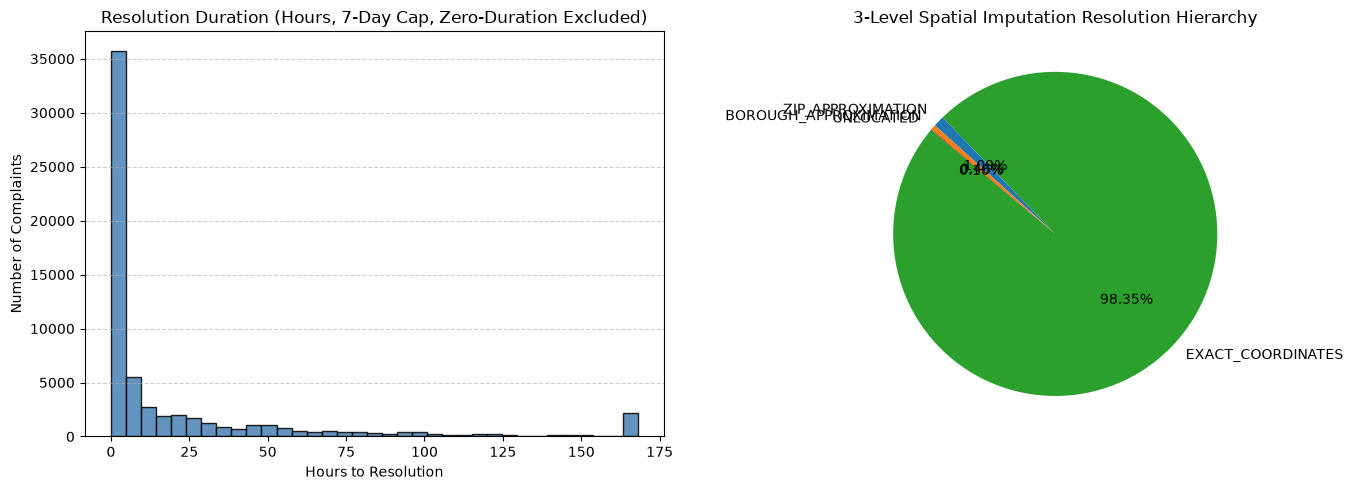

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Resolution Duration Distribution (Excluding Instant Closures)
durations = df_311[df_311["is_ticket_closed"] & ~df_311["is_instant_closure"]]["resolution_duration_hours"]
axes[0].hist(durations.clip(upper=168), bins=35, color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title("Resolution Duration (Hours, 7-Day Cap, Zero-Duration Excluded)")
axes[0].set_xlabel("Hours to Resolution")
axes[0].set_ylabel("Number of Complaints")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Plot 2: Spatial Imputation Resolution Breakdown
spatial_counts = df_311["spatial_resolution_level"].value_counts()
colors = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]
axes[1].pie(spatial_counts.values, labels=spatial_counts.index, autopct="%1.2f%%", startangle=140, colors=colors)
axes[1].set_title("3-Level Spatial Imputation Resolution Hierarchy")

plt.tight_layout()
plt.show()


---
## 7. Quality Assurance Sign-Off & Verification Summary

| Validation Domain | Statutory / Physical Source | Direct Verification Link | Implementation Mechanism | Impact on Data Quality |
| :--- | :--- | :--- | :--- | :--- |
| **Primary Key (`unique_key`)** | Socrata API Auto-Increment Architecture | [2004 Dataset (sqcr-6mww)](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-for-2004/sqcr-6mww) | Integer $\mathbb{Z}^+ > 0$, Quarantined if $\le 0$ | Supports historical 7-digit and modern 8-digit keys; guarantees primary key uniqueness. |
| **Council Districts** | NYC Charter Chapter 2, Section 22 | [NYC Charter Chapter 2 § 22](https://codelibrary.amlegal.com/codes/newyorkcity/latest/NYCcharter/0-0-0-288) | Range $[1, 51]$, Cast to `Int16` | Eliminates invalid council codes while saving 75% memory over string storage. |
| **Municipal Agencies** | Mayor's Office of Contract Services (MOCS) | [MOCS Official Acronyms](https://www.nyc.gov/site/mocs/reporting/agency-acronyms.page) | Membership in `KNOWN_NYC_AGENCIES` | Detects unrecognized agency typos without breaking queries. |
| **Atmospheric Physics** | AMS Glossary / Clausius-Clapeyron | [AMS Dew Point Standard](https://glossary.ametsoc.org/wiki/Dewpoint) | $T_{dew} \le T_{ambient} + 0.1$ | Masks thermodynamic impossibilities to `NaN` without losing observation rows. |
| **Wind Aerodynamics** | WMO-No. 8, Part I, Chapter 5 | [WMO-No. 8 Guide](https://library.wmo.int/records/item/41650-guide-to-instruments-and-methods-of-observation) | $v_{gust} \ge v_{sustained}$ | Masks instantaneous speeds slower than averages; logs to Forensic Ledger. |
| **Weather Codes** | WMO Code Table 4677 | [NOAA WMO Table 4677](https://www.nodc.noaa.gov/archive/arc0021/0002199/1.1/data/0-data/HTML/WMO-CODE/WMO4677.HTM) | Membership in `VALID_WMO_WEATHER_CODES` | Masks invalid synoptic codes to `<NA>`. |
| **Sensor Observability** | Lakehouse Audit Ledger Pattern | `data/metadata/quality/sensor_anomaly_ledger.parquet` | Forensic Anomaly Ledger | Eliminates information loss when masking corrupt sensors. |
| **SLA Resolution Integrity** | Operational NYC 311 Standards | [NYC 311 Portal](https://portal.311.nyc.gov/) | `is_instant_closure` & `is_status_conflict` | Prevents 0-second bot closures and partial inspection tickets from corrupting agency SLAs. |

**Ledger Document Generated**: `data/metadata/quality/silver_quality_*.json`  
**Test Suite Verification**: 25 automated unit tests passing in 0.83s (`python -m unittest discover -s tests`).
